# **Import**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import hashlib
from collections import defaultdict
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
import tensorflow as tf

print("Libraries imported successfully!")

Libraries imported successfully!


# **Data Loading & Extraction**

In [2]:
#Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
#Set Project Path
project_path = "/content/drive/MyDrive/PlantDiseaseProject"

print(os.listdir(project_path))

['Plant_leaf_diseases_dataset_without_augmentation.zip', 'PlantVillage']


In [4]:
#Extract Dataset
zip_path = os.path.join(
    project_path,
    "Plant_leaf_diseases_dataset_without_augmentation.zip"
)

extract_path = "/content/PlantVillage"

os.makedirs(extract_path, exist_ok=True)

!unzip -q -o "{zip_path}" -d "{extract_path}"

print("Dataset extracted successfully!")
print(os.listdir(extract_path)[:10])

Dataset extracted successfully!
['Plant_leave_diseases_dataset_without_augmentation']


In [5]:
#Inspect Folder Structure
for root, dirs, files in os.walk(extract_path):
    if dirs:
        print("Folder:", root)
        print("Subfolders:", dirs[:10])

Folder: /content/PlantVillage
Subfolders: ['Plant_leave_diseases_dataset_without_augmentation']
Folder: /content/PlantVillage/Plant_leave_diseases_dataset_without_augmentation
Subfolders: ['Cherry___Powdery_mildew', 'Tomato___Early_blight', 'Blueberry___healthy', 'Grape___Esca_(Black_Measles)', 'Tomato___healthy', 'Cherry___healthy', 'Grape___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Apple___Black_rot']


# **Identify Dataset Path & Classes**

In [6]:
# Define the correct dataset path
dataset_path = os.path.join(
    extract_path,
    "Plant_leave_diseases_dataset_without_augmentation"
)

# Count Classes
classes = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]

print("Number of Classes:", len(classes))

print("\nClasses:")
for c in sorted(classes):
    print(c)

Number of Classes: 39

Classes:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Background_without_leaves
Blueberry___healthy
Cherry___Powdery_mildew
Cherry___healthy
Corn___Cercospora_leaf_spot Gray_leaf_spot
Corn___Common_rust
Corn___Northern_Leaf_Blight
Corn___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___healthy


# **Count Images**

In [7]:
# Count images in each class
class_counts = {}

for c in classes:
    class_path = os.path.join(dataset_path, c)

    images = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    class_counts[c] = len(images)

# Create DataFrame
df_counts = pd.DataFrame(
    list(class_counts.items()),
    columns=['Class', 'Number of Images']
)

# Display results
df_counts = df_counts.sort_values(
    by='Class'
).reset_index(drop=True)

print(df_counts)

print("\nTotal Images:", df_counts['Number of Images'].sum())

                                            Class  Number of Images
0                              Apple___Apple_scab               630
1                               Apple___Black_rot               621
2                        Apple___Cedar_apple_rust               275
3                                 Apple___healthy              1645
4                       Background_without_leaves              1143
5                             Blueberry___healthy              1502
6                         Cherry___Powdery_mildew              1052
7                                Cherry___healthy               854
8      Corn___Cercospora_leaf_spot Gray_leaf_spot               513
9                              Corn___Common_rust              1192
10                    Corn___Northern_Leaf_Blight               985
11                                 Corn___healthy              1162
12                              Grape___Black_rot              1180
13                   Grape___Esca_(Black_Measles

# **Class Distribution**

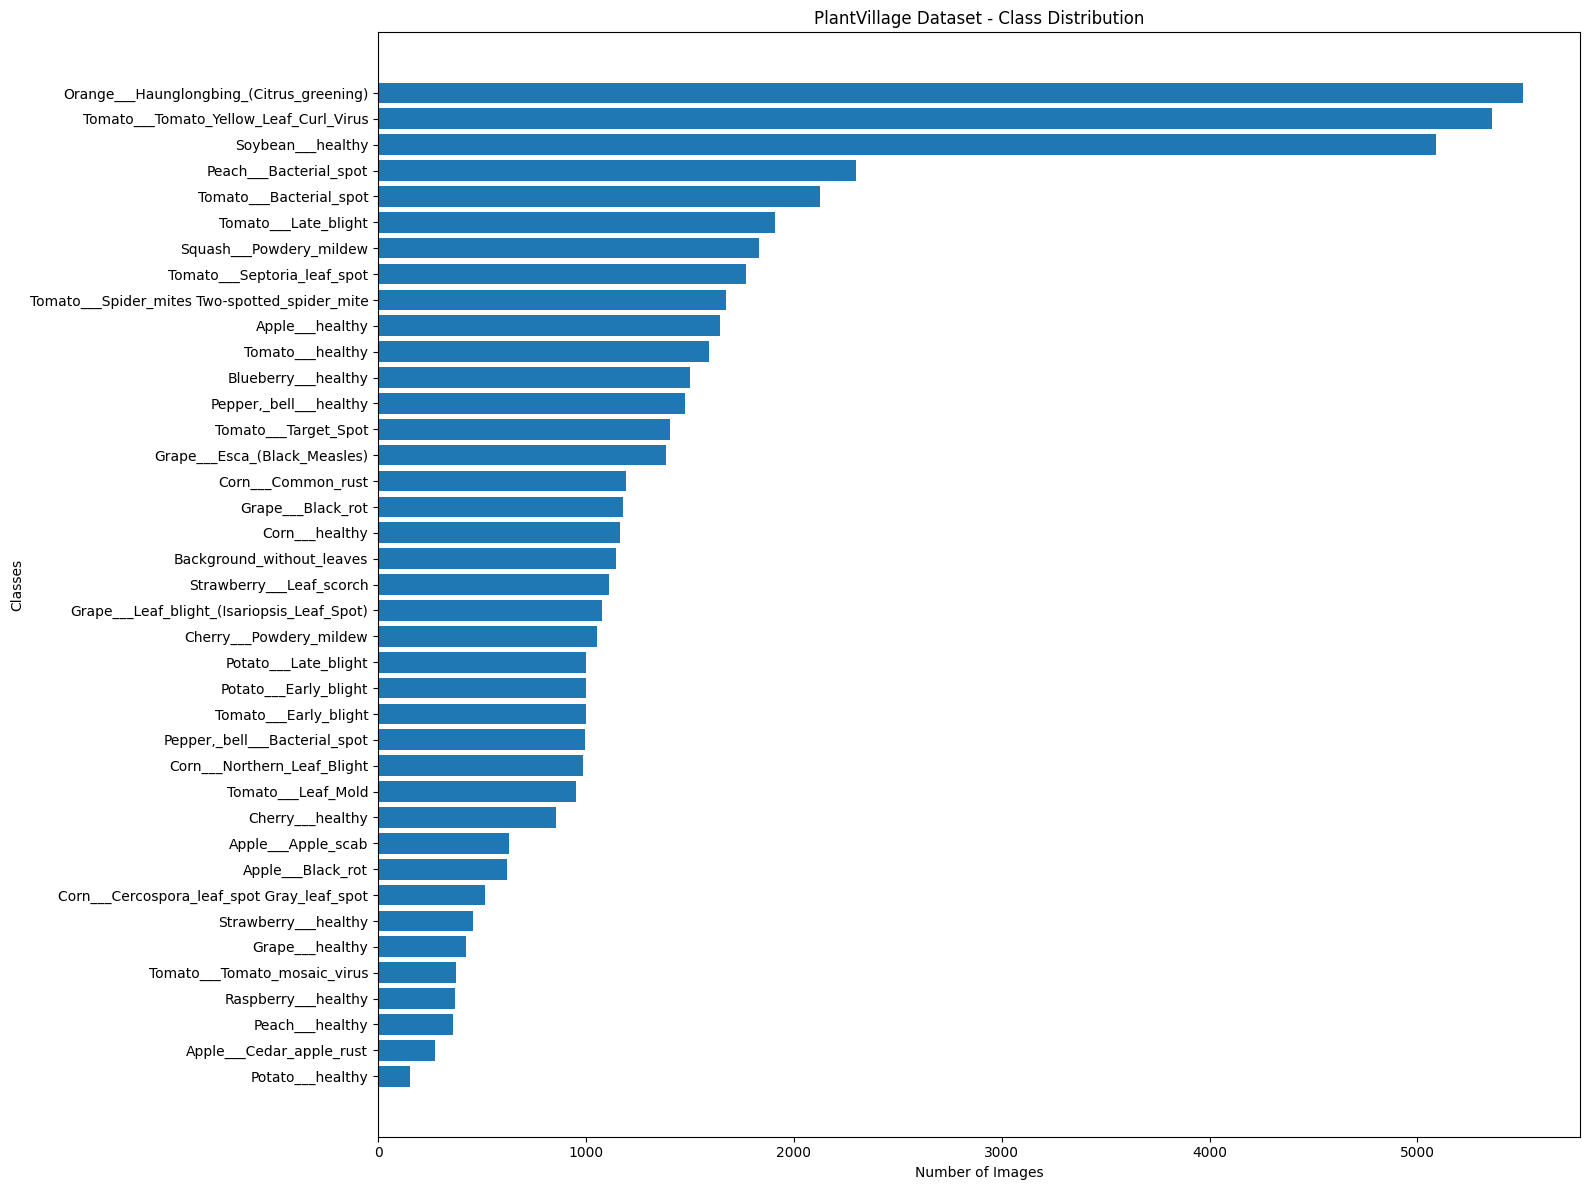

In [8]:
# Visualize Class Distribution

plt.figure(figsize=(16, 12))

sorted_counts = dict(
    sorted(class_counts.items(), key=lambda x: x[1])
)

plt.barh(
    list(sorted_counts.keys()),
    list(sorted_counts.values())
)

plt.xlabel("Number of Images")
plt.ylabel("Classes")
plt.title("PlantVillage Dataset - Class Distribution")

plt.tight_layout()
plt.show()

# **Image Quality Check**

In [9]:
# Check for corrupted images

corrupted_images = []
total_checked = 0

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            total_checked += 1

            try:
                with Image.open(file_path) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(file_path)

print("Total Images Checked:", total_checked)
print("Corrupted Images:", len(corrupted_images))

if corrupted_images:
    print("\nCorrupted Images List:")
    for img in corrupted_images:
        print(img)
else:
    print("\nAll images are valid")

Total Images Checked: 55448
Corrupted Images: 0

All images are valid


# **Check Duplicate Images**

In [10]:
# Check for duplicate images

image_hashes = defaultdict(list)

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_path):
        file_path = os.path.join(class_path, filename)

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):

            with open(file_path, 'rb') as f:
                image_hash = hashlib.md5(f.read()).hexdigest()

            image_hashes[image_hash].append(file_path)

# Identify duplicates
duplicate_groups = [
    paths for paths in image_hashes.values()
    if len(paths) > 1
]

duplicate_images = sum(
    len(paths) - 1 for paths in duplicate_groups
)

print("Total Unique Image Hashes:", len(image_hashes))
print("Duplicate Groups:", len(duplicate_groups))
print("Extra Duplicate Images:", duplicate_images)

Total Unique Image Hashes: 55425
Duplicate Groups: 22
Extra Duplicate Images: 23


In [11]:
# Analyze duplicate images across classes

same_class_duplicates = 0
different_class_duplicates = 0

for group in duplicate_groups:

    group_classes = [
        os.path.basename(os.path.dirname(path))
        for path in group
    ]

    unique_classes = set(group_classes)

    if len(unique_classes) == 1:
        same_class_duplicates += 1
    else:
        different_class_duplicates += 1

    print("\nDuplicate Group:")
    for path in group:
        print("Class:", os.path.basename(os.path.dirname(path)))
        print("File:", os.path.basename(path))

    print("-" * 50)

print("\nSame Class Duplicate Groups:", same_class_duplicates)
print("Different Class Duplicate Groups:", different_class_duplicates)


Duplicate Group:
Class: Tomato___healthy
File: image (943).JPG
Class: Tomato___healthy
File: image (992).JPG
--------------------------------------------------

Duplicate Group:
Class: Tomato___healthy
File: image (474).JPG
Class: Tomato___healthy
File: image (553).JPG
--------------------------------------------------

Duplicate Group:
Class: Tomato___healthy
File: image (1457).JPG
Class: Tomato___healthy
File: image (477).JPG
--------------------------------------------------

Duplicate Group:
Class: Tomato___healthy
File: image (682).JPG
Class: Tomato___healthy
File: image (1027).JPG
--------------------------------------------------

Duplicate Group:
Class: Tomato___healthy
File: image (1305).JPG
Class: Tomato___healthy
File: image (55).JPG
--------------------------------------------------

Duplicate Group:
Class: Tomato___healthy
File: image (984).JPG
Class: Tomato___healthy
File: image (1311).JPG
--------------------------------------------------

Duplicate Group:
Class: Apple_

In [12]:
# Identify extra duplicate copies
duplicate_paths_to_remove = {
    path
    for group in duplicate_groups
    for path in group[1:]
}

# Create a clean dataset list
image_paths = []
labels = []

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for filename in os.listdir(class_path):

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):

            file_path = os.path.join(class_path, filename)

            if file_path not in duplicate_paths_to_remove:
                image_paths.append(file_path)
                labels.append(class_name)

# Create DataFrame
df_clean = pd.DataFrame({
    'image_path': image_paths,
    'label': labels
})

print("Original Images:", total_checked)
print("Removed Duplicate Copies:", len(duplicate_paths_to_remove))
print("Clean Dataset Images:", len(df_clean))
print("Number of Classes:", df_clean['label'].nunique())

Original Images: 55448
Removed Duplicate Copies: 23
Clean Dataset Images: 55425
Number of Classes: 39


# **Split Dataset**

In [13]:
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42,
    stratify=df_clean['label']
)

print("Training Images:", len(train_df))
print("Temporary Images:", len(temp_df))

Training Images: 38797
Temporary Images: 16628


In [14]:
#Split Validation and Testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['label']
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nTotal Images:",
      len(train_df) + len(val_df) + len(test_df))

Training Images: 38797
Validation Images: 8314
Testing Images: 8314

Total Images: 55425


In [15]:
print("Classes in Training:", train_df['label'].nunique())
print("Classes in Validation:", val_df['label'].nunique())
print("Classes in Testing:", test_df['label'].nunique())

Classes in Training: 39
Classes in Validation: 39
Classes in Testing: 39


In [16]:
# Check dataset split distribution

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nTotal Images:",
      len(train_df) + len(val_df) + len(test_df))

print("\nTraining Percentage:",
      round(len(train_df) / len(df_clean) * 100, 2), "%")

print("Validation Percentage:",
      round(len(val_df) / len(df_clean) * 100, 2), "%")

print("Testing Percentage:",
      round(len(test_df) / len(df_clean) * 100, 2), "%")

Training Images: 38797
Validation Images: 8314
Testing Images: 8314

Total Images: 55425

Training Percentage: 70.0 %
Validation Percentage: 15.0 %
Testing Percentage: 15.0 %


# **Check Missing Values**

In [17]:
# Check missing values in each dataset

datasets = {
    "Training": train_df,
    "Validation": val_df,
    "Testing": test_df
}

for name, df in datasets.items():

    print(f"\n{name} Dataset")

    print("Missing Values:")
    print(df.isnull().sum())

    print("Empty Image Paths:",
          (df['image_path'] == '').sum())

    print("Empty Labels:",
          (df['label'] == '').sum())

    print("Duplicate Paths:",
          df['image_path'].duplicated().sum())


Training Dataset
Missing Values:
image_path    0
label         0
dtype: int64
Empty Image Paths: 0
Empty Labels: 0
Duplicate Paths: 0

Validation Dataset
Missing Values:
image_path    0
label         0
dtype: int64
Empty Image Paths: 0
Empty Labels: 0
Duplicate Paths: 0

Testing Dataset
Missing Values:
image_path    0
label         0
dtype: int64
Empty Image Paths: 0
Empty Labels: 0
Duplicate Paths: 0


In [18]:
# Check if image files exist

for name, df in datasets.items():

    missing_files = sum(
        not os.path.isfile(path)
        for path in df['image_path']
    )

    print(name, "Missing Files:", missing_files)

Training Missing Files: 0
Validation Missing Files: 0
Testing Missing Files: 0


# **Label Encoding**

In [19]:
# Create label encoder
label_encoder = LabelEncoder()

# Fit only on training labels
train_labels = label_encoder.fit_transform(train_df['label'])

# Transform validation and testing labels
val_labels = label_encoder.transform(val_df['label'])
test_labels = label_encoder.transform(test_df['label'])

print("Number of Classes:", len(label_encoder.classes_))

print("\nFirst 10 Class Names:")
print(label_encoder.classes_[:10])

print("\nTraining Labels Shape:", train_labels.shape)
print("Validation Labels Shape:", val_labels.shape)
print("Testing Labels Shape:", test_labels.shape)

Number of Classes: 39

First 10 Class Names:
['Apple___Apple_scab' 'Apple___Black_rot' 'Apple___Cedar_apple_rust'
 'Apple___healthy' 'Background_without_leaves' 'Blueberry___healthy'
 'Cherry___Powdery_mildew' 'Cherry___healthy'
 'Corn___Cercospora_leaf_spot Gray_leaf_spot' 'Corn___Common_rust']

Training Labels Shape: (38797,)
Validation Labels Shape: (8314,)
Testing Labels Shape: (8314,)


In [20]:
from tensorflow.keras.utils import to_categorical

# One-hot encode labels
num_classes = len(label_encoder.classes_)

y_train = to_categorical(train_labels, num_classes=num_classes)
y_val = to_categorical(val_labels, num_classes=num_classes)
y_test = to_categorical(test_labels, num_classes=num_classes)

print("Training Labels Shape:", y_train.shape)
print("Validation Labels Shape:", y_val.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nNumber of Ones:", np.sum(y_train[0]))

Training Labels Shape: (38797, 39)
Validation Labels Shape: (8314, 39)
Testing Labels Shape: (8314, 39)

Number of Ones: 1.0


# **Normalization**

In [21]:
IMG_SIZE = 224

def preprocess_image(image_path):
    # Read image file
    image = tf.io.read_file(image_path)

    # Decode image and convert it to RGB
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Convert pixel values from 0-255 to 0-1
    image = tf.image.convert_image_dtype(image, tf.float32)

    # Resize image
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])

    # Set fixed image shape
    image = tf.ensure_shape(image, [224, 224, 3])

    return image

Image Shape: (224, 224, 3)
Data Type: <dtype: 'float32'>
Minimum Value: 0.0
Maximum Value: 0.827889


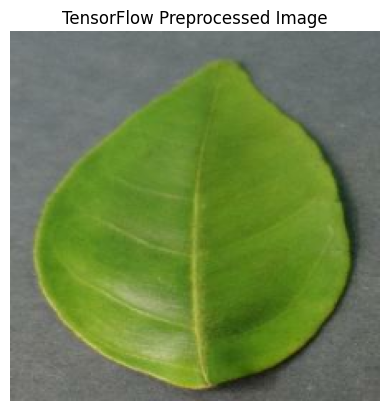

In [22]:
sample_path = train_df.iloc[0]['image_path']

processed_image = preprocess_image(sample_path)

print("Image Shape:", processed_image.shape)
print("Data Type:", processed_image.dtype)
print("Minimum Value:", tf.reduce_min(processed_image).numpy())
print("Maximum Value:", tf.reduce_max(processed_image).numpy())

plt.imshow(processed_image.numpy())
plt.title("TensorFlow Preprocessed Image")
plt.axis("off")
plt.show()

# **Dataset Function**

In [23]:
def create_dataset(
    dataframe,
    labels,
    batch_size=32,
    shuffle=False
):

    dataset = tf.data.Dataset.from_tensor_slices(
        (dataframe['image_path'].values, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda path, label: (
            preprocess_image(path), label
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [24]:
BATCH_SIZE = 32

train_dataset = create_dataset(
    train_df, y_train, BATCH_SIZE, shuffle=True
)

val_dataset = create_dataset(
    val_df, y_val, BATCH_SIZE
)

test_dataset = create_dataset(
    test_df, y_test, BATCH_SIZE
)
print("Datasets Created Successfully!")

Datasets Created Successfully!


In [25]:
images, labels = next(iter(train_dataset))

print("Images Shape:", images.shape)
print("Labels Shape:", labels.shape)

print("Image Data Type:", images.dtype)
print("Image Minimum:", tf.reduce_min(images).numpy())
print("Image Maximum:", tf.reduce_max(images).numpy())

Images Shape: (32, 224, 224, 3)
Labels Shape: (32, 39)
Image Data Type: <dtype: 'float32'>
Image Minimum: 0.0
Image Maximum: 1.0


# **Class Imbalance (Class Weights)**

In [26]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Define class indices
class_indices = np.arange(num_classes)

# Calculate balanced class weights
weights = compute_class_weight(
    class_weight='balanced',
    classes=class_indices,
    y=train_labels
)

# Create dictionary
class_weights = {
    i: float(weight)
    for i, weight in enumerate(weights)
}

print("Number of Class Weights:", len(class_weights))

print("\nMinimum Weight:", min(weights))
print("Maximum Weight:", max(weights))

print("\nClass Weights:")
for i, class_name in enumerate(label_encoder.classes_):
    print(class_name, ":", round(class_weights[i], 3))

Number of Class Weights: 39

Minimum Weight: 0.2580531444344674
Maximum Weight: 9.384857281083697

Class Weights:
Apple___Apple_scab : 2.256
Apple___Black_rot : 2.287
Apple___Cedar_apple_rust : 5.154
Apple___healthy : 0.867
Background_without_leaves : 1.245
Blueberry___healthy : 0.947
Cherry___Powdery_mildew : 1.352
Cherry___healthy : 1.664
Corn___Cercospora_leaf_spot Gray_leaf_spot : 2.771
Corn___Common_rust : 1.193
Corn___Northern_Leaf_Blight : 1.442
Corn___healthy : 1.224
Grape___Black_rot : 1.204
Grape___Esca_(Black_Measles) : 1.028
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1.321
Grape___healthy : 3.361
Orange___Haunglongbing_(Citrus_greening) : 0.258
Peach___Bacterial_spot : 0.619
Peach___healthy : 3.948
Pepper,_bell___Bacterial_spot : 1.425
Pepper,_bell___healthy : 0.961
Potato___Early_blight : 1.421
Potato___Late_blight : 1.421
Potato___healthy : 9.385
Raspberry___healthy : 3.826
Soybean___healthy : 0.279
Squash___Powdery_mildew : 0.775
Strawberry___Leaf_scorch : 1.282
Strawb

In [27]:
# Convert class weights to TensorFlow tensor
class_weights_tensor = tf.constant(
    [class_weights[i] for i in range(num_classes)],
    dtype=tf.float32
)

# Assign a weight to each image
def add_sample_weights(images, labels):

    # Get class index from one-hot label
    class_ids = tf.argmax(
        labels,
        axis=1,
        output_type=tf.int32
    )

    # Get the corresponding weight
    sample_weights = tf.gather(
        class_weights_tensor,
        class_ids
    )

    return images, labels, sample_weights


# Rebuild training dataset with shuffling
train_dataset_weighted = tf.data.Dataset.from_tensor_slices(
    (train_df['image_path'].values, y_train)
)

train_dataset_weighted = train_dataset_weighted.shuffle(
    buffer_size=len(train_df),
    seed=42,
    reshuffle_each_iteration=True
)

train_dataset_weighted = train_dataset_weighted.map(
    lambda path, label: (preprocess_image(path), label),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset_weighted = train_dataset_weighted.batch(BATCH_SIZE)

train_dataset_weighted = train_dataset_weighted.map(
    add_sample_weights,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset_weighted = train_dataset_weighted.prefetch(
    tf.data.AUTOTUNE
)

print("Weighted Training Dataset Created Successfully!")

Weighted Training Dataset Created Successfully!


In [28]:
images, labels, sample_weights = next(
    iter(train_dataset_weighted)
)

print("Images Shape:", images.shape)
print("Labels Shape:", labels.shape)
print("Sample Weights Shape:", sample_weights.shape)

print("\nMinimum Sample Weight:",
      tf.reduce_min(sample_weights).numpy())

print("Maximum Sample Weight:",
      tf.reduce_max(sample_weights).numpy())

Images Shape: (32, 224, 224, 3)
Labels Shape: (32, 39)
Sample Weights Shape: (32,)

Minimum Sample Weight: 0.25805315
Maximum Sample Weight: 5.1543775


# **Augmentation**

In [37]:
# Create augmentation layers only once
rotation_layer = tf.keras.layers.RandomRotation(
    factor=0.25,
    fill_mode='reflect'
)

zoom_layer = tf.keras.layers.RandomZoom(
    height_factor=(-0.15, 0.15),
    width_factor=(-0.15, 0.15),
    fill_mode='reflect'
)

def augment_image(image):
    image = rotation_layer(image, training=True)
    image = zoom_layer(image, training=True)
    return image



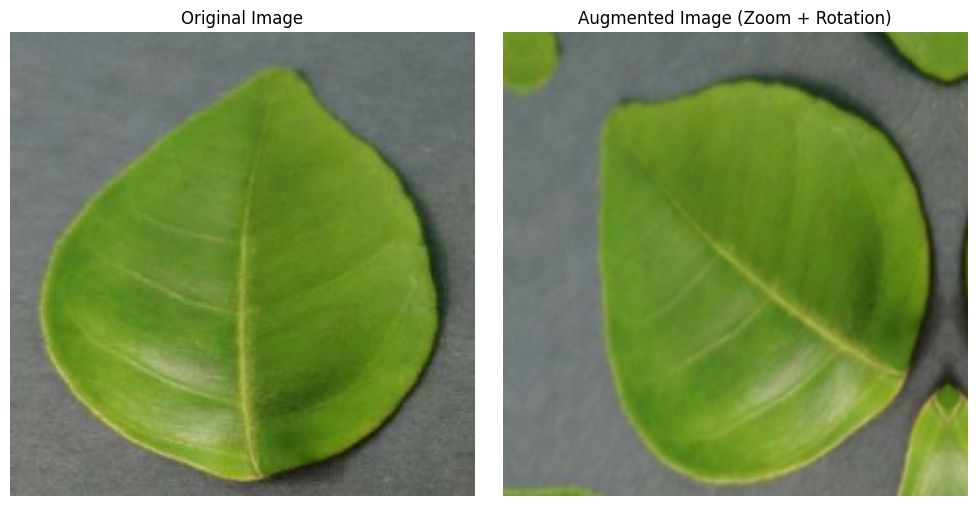

In [36]:


import matplotlib.pyplot as plt

# Get a sample image
sample_path = train_df.iloc[0]['image_path']

# Preprocess original image
original_image = preprocess_image(sample_path)

# Apply augmentation
augmented_image = augment_image(original_image)

# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image.numpy())
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(tf.clip_by_value(augmented_image, 0, 1).numpy())
plt.title("Augmented Image (Zoom + Rotation)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [31]:

def preprocess_and_augment(image_path, label):
    image = preprocess_image(image_path)
    image = augment_image(image)
    return image, label


train_dataset_augmented = tf.data.Dataset.from_tensor_slices(
    (train_df['image_path'].values, y_train)
)

train_dataset_augmented = train_dataset_augmented.shuffle(
    buffer_size=len(train_df),
    seed=42,
    reshuffle_each_iteration=True
)

train_dataset_augmented = train_dataset_augmented.map(
    preprocess_and_augment,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset_augmented = train_dataset_augmented.batch(BATCH_SIZE)

train_dataset_augmented = train_dataset_augmented.map(
    add_sample_weights,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset_augmented = train_dataset_augmented.prefetch(
    tf.data.AUTOTUNE
)


In [32]:
images, labels, sample_weights = next(
    iter(train_dataset_augmented)
)

print("Images Shape:", images.shape)
print("Labels Shape:", labels.shape)
print("Sample Weights Shape:", sample_weights.shape)

print("Image Data Type:", images.dtype)
print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
print("Maximum Pixel Value:", tf.reduce_max(images).numpy())


Images Shape: (32, 224, 224, 3)
Labels Shape: (32, 39)
Sample Weights Shape: (32,)
Image Data Type: <dtype: 'float32'>
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
